# Khởi tạo môi trường để thực hiện

In [ ]:
import json
import re
import os
import pandas as pd
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import OneHotEncoder
# Đường dẫn thư mục chứa dữ liệu
DATA_PATH = "./dataset/csv/"
# Tự động tạo thư mục nếu chưa tồn tại để bạn dễ dàng upload file vào
if not os.path.exists(DATA_PATH):
    os.makedirs(DATA_PATH)
    print(f"Đã tạo thư mục trống tại: {DATA_PATH}")
    print("HÃY THEO DÕI: Vui lòng upload các file 'train.csv', 'validation.csv', 'test.csv', 'heroes.csv' vào thư mục này.")
else:
    print(f"Thư mục dữ liệu đã tồn tại: {DATA_PATH}")
try:
    train_df = pd.read_csv(DATA_PATH + "train.csv", dtype=str)
    val_df = pd.read_csv(DATA_PATH + "validation.csv", dtype=str)
    test_df = pd.read_csv(DATA_PATH + "test.csv", dtype=str)
    heroes_df = pd.read_csv(DATA_PATH + "heroes.csv", dtype=str)
    valid_hero_ids = set(heroes_df["hero_id"].unique())
    print("Đã tải dữ liệu thành công!")
except FileNotFoundError as e:
    print(f"Lỗi: Không tìm thấy file dữ liệu trong '{DATA_PATH}'. Chi tiết lỗi: {e}")
    print("Hãy đảm bảo bạn đã tải đầy đủ các file dữ liệu lên đúng thư mục.")

Thư mục dữ liệu đã tồn tại: ./dataset/csv/
Đã tải dữ liệu thành công!


# Xây dựng hàm Cleaning Data (Làm sạch)

In [ ]:
def clean_dataset(df, is_train=True):
    df = df.copy()

    # 1. Làm sạch nhãn team_a_win (nếu có)
    if 'team_a_win' in df.columns:
        df['team_a_win'] = df['team_a_win'].astype(str).str.lower().map({'true': 1, 'false': 0})
        if is_train:
            # Loại bỏ dòng thiếu nhãn ở tập Train (nếu có)
            df = df.dropna(subset=['team_a_win'])
            df['team_a_win'] = df['team_a_win'].astype(int)

    # 2. Chuẩn hóa chuỗi (strip khoảng trắng)
    for col in ['team_a_side', 'patch_id']:
        if col in df.columns:
            df[col] = df[col].astype(str).str.strip()

    # 3. Parse JSON đội hình
    def parse_heroes(val):
        try:
            ids = json.loads(val)
            if isinstance(ids, list) and len(ids) == 5:
                return ids
        except:
            pass
        return ["unknown"] * 5  # Điền fallback nếu lỗi JSON/sai số lượng

    df['team_a_heroes_parsed'] = df['team_a_heroes'].apply(parse_heroes)
    df['team_b_heroes_parsed'] = df['team_b_heroes'].apply(parse_heroes)

    return df

# Thực hiện làm sạch dữ liệu trước
train_clean = clean_dataset(train_df, is_train=True)
val_clean = clean_dataset(val_df, is_train=False)
test_clean = clean_dataset(test_df, is_train=False)

# Định nghĩa và Fit Vectorizer
class HeroBagEncoder(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.vocab_ = []
        self.hero_to_idx_ = {}

    def fit(self, X, y=None):
        # Build từ điển tướng từ tập Train
        unique_heroes = set()
        for _, row in X.iterrows():
            unique_heroes.update(row['team_a_heroes_parsed'])
            unique_heroes.update(row['team_b_heroes_parsed'])

        # Loại bỏ ID không hợp lệ nếu có
        self.vocab_ = sorted(list(unique_heroes))
        self.hero_to_idx_ = {h: i for i, h in enumerate(self.vocab_)}
        return self

    def transform(self, X):
        n_samples = len(X)
        n_features = len(self.vocab_)
        matrix = np.zeros((n_samples, n_features), dtype=np.int8)

        for i, (_, row) in enumerate(X.iterrows()):
            # Team A +1
            for h in row['team_a_heroes_parsed']:
                if h in self.hero_to_idx_:
                    matrix[i, self.hero_to_idx_[h]] += 1
            # Team B -1
            for h in row['team_b_heroes_parsed']:
                if h in self.hero_to_idx_:
                    matrix[i, self.hero_to_idx_[h]] -= 1

        feature_names = [f"hero_{h}" for h in self.vocab_]
        return pd.DataFrame(matrix, columns=feature_names, index=X.index)

# Fit encoder trên Train
hero_encoder = HeroBagEncoder()
X_train_heroes = hero_encoder.fit_transform(train_clean)
X_val_heroes = hero_encoder.transform(val_clean)
X_test_heroes = hero_encoder.transform(test_clean)

print("Đã làm sạch dữ liệu và biến đổi đặc trưng thành công!")

Đã làm sạch dữ liệu và biến đổi đặc trưng thành công!


# Feature Engineering / Vectorization (Biến đổi tướng)

In [ ]:
class HeroBagEncoder(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.vocab_ = []
        self.hero_to_idx_ = {}

    def fit(self, X, y=None):
        # Build từ điển tướng từ tập Train
        unique_heroes = set()
        for _, row in X.iterrows():
            unique_heroes.update(row['team_a_heroes_parsed'])
            unique_heroes.update(row['team_b_heroes_parsed'])

        # Loại bỏ ID không hợp lệ nếu có
        self.vocab_ = sorted(list(unique_heroes))
        self.hero_to_idx_ = {h: i for i, h in enumerate(self.vocab_)}
        return self

    def transform(self, X):
        n_samples = len(X)
        n_features = len(self.vocab_)
        matrix = np.zeros((n_samples, n_features), dtype=np.int8)

        for i, (_, row) in enumerate(X.iterrows()):
            # Team A +1
            for h in row['team_a_heroes_parsed']:
                if h in self.hero_to_idx_:
                    matrix[i, self.hero_to_idx_[h]] += 1
            # Team B -1
            for h in row['team_b_heroes_parsed']:
                if h in self.hero_to_idx_:
                    matrix[i, self.hero_to_idx_[h]] -= 1

        feature_names = [f"hero_{h}" for h in self.vocab_]
        return pd.DataFrame(matrix, columns=feature_names, index=X.index)

# Fit encoder trên Train
hero_encoder = HeroBagEncoder()
X_train_heroes = hero_encoder.fit_transform(train_clean)
X_val_heroes = hero_encoder.transform(val_clean)
X_test_heroes = hero_encoder.transform(test_clean)

# Mã hóa Categorical Features (team_a_side, patch_id)

In [ ]:
cat_features = ['team_a_side', 'patch_id']

# OneHotEncoder xử lý unseen categories cho patch/side
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# Fit trên Train
X_train_cat_raw = ohe.fit_transform(train_clean[cat_features])
cat_cols = ohe.get_feature_names_out(cat_features)

X_train_cat = pd.DataFrame(X_train_cat_raw, columns=cat_cols, index=train_clean.index)
X_val_cat = pd.DataFrame(ohe.transform(val_clean[cat_features]), columns=cat_cols, index=val_clean.index)
X_test_cat = pd.DataFrame(ohe.transform(test_clean[cat_features]), columns=cat_cols, index=test_clean.index)

# Tổng hợp dữ liệu đầu ra (Final Output)

In [ ]:
# Kết hợp Hero features + Categorical features
X_train = pd.concat([X_train_heroes, X_train_cat], axis=1)
y_train = train_clean['team_a_win']

X_val = pd.concat([X_val_heroes, X_val_cat], axis=1)
y_val = val_clean['team_a_win']

X_test = pd.concat([X_test_heroes, X_test_cat], axis=1)
y_test = test_clean['team_a_win']

print(f"Kích thước tập Train: {X_train.shape}")
print(f"Kích thước tập Validation: {X_val.shape}")
print(f"Kích thước tập Test: {X_test.shape}")

# Xuất file đã tiền xử lý để sử dụng cho bước huấn luyện mô hình (Model Training)
X_train.to_csv("X_train_preprocessed.csv", index=False)
y_train.to_csv("y_train.csv", index=False)
X_val.to_csv("X_val_preprocessed.csv", index=False)
y_val.to_csv("y_val.csv", index=False)
X_test.to_csv("X_test_preprocessed.csv", index=False)
y_test.to_csv("y_test.csv", index=False)

Kích thước tập Train: (231, 88)
Kích thước tập Validation: (28, 88)
Kích thước tập Test: (40, 88)


# Phân tích dữ liệu đầu ra cuối cùng

,hero_024aa135-6f50-5cf1-b55c-b3429a526b6b,hero_0291070e-0576-5faf-b755-52780b69f517,hero_033880d4-23f4-529b-b08f-e9ff96e40135,hero_033fc0fc-5f17-527d-bbf1-7b015c35625c,hero_05f0a49e-dd88-5991-b1f6-fb6a193247b6,hero_07d3ecae-1797-5a5b-a789-bd4dad41df3e,hero_0800854f-1e27-5529-a00a-56987f6c3c0e,hero_0b9d9c4b-1691-5b76-9f64-11e565923cf2,hero_0ce5c692-68cc-5460-a789-6ab8f00bb358,hero_1137f995-fa1c-59e0-a4b6-36ef629fba14,...,hero_f6a7ee98-4b62-55b4-aa80-57ce5d792bf2,hero_fbf501c9-2be3-5b37-a25b-73b23ce76088,hero_fc4e780d-20ef-5d0b-9f60-3f7a45e3aff2,hero_fd8c9dae-0c2c-5a52-bdd5-d74636fbc34c,hero_ff6904fe-5f60-5f37-92bb-02f1229e2589,team_a_side_blue,team_a_side_red,patch_id_aov:vn:2026-02-14,patch_id_aov:vn:2026-03-11,patch_id_aov:vn:2026-04-08
0,0,0,0,1,0,0,0,0,0,0,...,-1,0,0,0,0,0.0,1.0,1.0,0.0,0.0
1,0,0,0,0,1,0,0,0,0,0,...,0,1,0,0,1,1.0,0.0,1.0,0.0,0.0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0.0,1.0,1.0,0.0,0.0
3,0,0,0,-1,0,0,0,0,0,0,...,0,0,0,0,0,1.0,0.0,1.0,0.0,0.0
4,0,0,0,0,0,0,0,0,0,0,...,0,-1,0,0,0,0.0,1.0,1.0,0.0,0.0


Số cột đặc trưng tướng: 83
Số cột đặc trưng phân loại (patch/side): 5


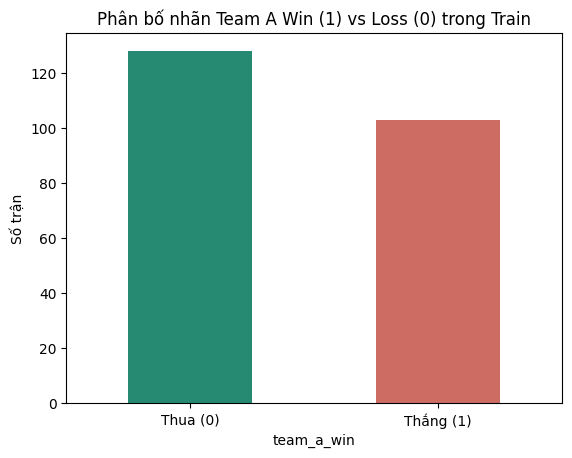

In [ ]:
# 1. Hiển thị 5 dòng đầu tiên của tập Train đã mã hóa để kiểm tra
display(X_train.head())

# 2. Kiểm tra tổng số cột đặc trưng Tướng và đặc trưng Patch/Side
print(f"Số cột đặc trưng tướng: {len(hero_encoder.vocab_)}")
print(f"Số cột đặc trưng phân loại (patch/side): {len(cat_cols)}")

# 3. Trực quan hóa phân bố nhãn (Team A Win/Loss) sau làm sạch
import matplotlib.pyplot as plt

y_train.value_counts().plot(kind='bar', color=['#258a71', '#cc6c62'])
plt.title("Phân bố nhãn Team A Win (1) vs Loss (0) trong Train")
plt.xticks([0, 1], ['Thua (0)', 'Thắng (1)'], rotation=0)
plt.ylabel("Số trận")
plt.show()